# Buổi C3: k láng giềng gần nhất (k-NN), hỏi hàng xóm rồi bỏ phiếu

**Hiện trường.** Anh Tú mở cửa hàng rượu vang. Một đại lý để lại **178 chai** đã xét nghiệm hóa học (13 chỉ số mỗi chai: độ cồn, magie, độ màu...) và ghi rõ chai thuộc **một trong ba giống nho** (A, B, C). Hôm nay có chai mới về, mới xét nghiệm xong **chưa dán nhãn giống**. Anh hỏi: *"Chai này giống nho nào, dựa vào những chai đã biết?"*

Cách nghĩ đời thường nhất: **tìm vài chai trông giống nó nhất rồi hỏi xem chúng thuộc giống nào.** Đó chính là k-NN.

**Câu hỏi của buổi này:** *"giống nhau" đo bằng gì, hỏi bao nhiêu hàng xóm, và khi nào cách này hỏng?*

**Mindset của người làm dữ liệu:** có những mô hình **không học công thức gì cả**, chỉ *nhớ* dữ liệu và tra cứu. Đơn giản đến mức nghi ngờ, nhưng nó dạy ta bài học quan trọng nhất về **thang đo** và **số cột thừa**.

**Lưu ý:** dữ liệu rượu là dữ liệu mẫu của scikit-learn để học. Buổi này dùng lại cú pháp từ A1 đến C2; chỉ giải thích điều **mới**.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Ý tưởng: tìm k chai giống nhất rồi bỏ phiếu |
| Chặng 2 | `KNeighborsClassifier`: `fit` chỉ nhớ, hồ sơ mô hình |
| Chặng 3 | Thang đo phá k-NN: một cột lấn át cả mười hai cột còn lại |
| Chặng 4 | Chọn k: nhớ cả nhiễu hay bỏ phiếu cả vườn |
| Chặng 5 | Đo khoảng cách kiểu nào, phiếu của ai nặng hơn |
| Chặng 6 | Giới hạn: cột nhiễu làm hàng xóm lạc đường |

## Chặng 1: Ý tưởng, tìm k chai giống nhất rồi bỏ phiếu

**Câu hỏi:** "giống nhau" nghĩa là gì với một chai rượu chỉ có vài con số?

Mỗi chai là **một điểm** trên bản đồ mà các **cột** là trục. Hai chai *giống nhau* nghĩa là hai điểm **gần nhau** trên bản đồ. Khoảng cách thẳng giữa hai điểm (như đo bằng thước) là **khoảng cách Euclid**: với hai cột, bằng căn bậc hai của (hiệu cột 1)² + (hiệu cột 2)².

Để nhìn được, ta tạm dùng **hai cột** (flavanoids và màu rượu), vẽ lên mặt phẳng.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(X.shape, "| class counts:", y.value_counts().sort_index().to_dict())
cols2 = ["flavanoids", "color_intensity"]
sc2 = StandardScaler().fit(X_train[cols2])
Z_train, Z_test = sc2.transform(X_train[cols2]), sc2.transform(X_test[cols2])
new_bottle = Z_test[8]
dist = np.sqrt(((Z_train - new_bottle) ** 2).sum(axis=1))
nearest = np.argsort(dist)[:5]
print("5 nearest distances:", dist[nearest].round(2), "| their classes:", y_train.values[nearest], "| true class of the new bottle:", y_test.values[8])

(178, 13) | class counts: {0: 59, 1: 71, 2: 48}
5 nearest distances: [0.39 0.63 0.67 0.68 0.73] | their classes: [0 0 1 1 0] | true class of the new bottle: 1


**Giải thích từng dòng**

- `from sklearn.datasets import load_wine`: bộ dữ liệu rượu vang: 178 chai, 13 cột số đo, 3 giống nho (mã 0, 1, 2).
- `X_train, X_test, y_train, y_test = train_test_split(..., stratify=y)`: (đã học) chia 75/25 giữ tỉ lệ ba giống. 133 chai học, 45 chai thi.
- `cols2 = ["flavanoids", "color_intensity"]`: danh sách hai tên cột ta tạm dùng để vẽ.
- `sc2 = StandardScaler().fit(X_train[cols2])`: (đã học ở B4) chuẩn hóa hai cột này, đo trên tập học. Ta tạm chuẩn hóa để vòng tròn trên hình trông tròn; lý do thật sự ở chặng 3.
- `Z_train, Z_test = sc2.transform(...), sc2.transform(...)`: bảng đã chuẩn hóa dạng mảng numpy (`Z` là thói quen đặt tên cho dữ liệu đã chuẩn hóa).
- `new_bottle = Z_test[8]`: lấy **chai thi thứ chín** (vị trí 8, đếm từ 0) làm "chai mới": mảng hai số (hai cột đã chuẩn hóa). Ta cố ý chọn một chai *khó*, nằm giữa hai đám.
- `dist = np.sqrt(((Z_train - new_bottle) ** 2).sum(axis=1))`: **khoảng cách Euclid từ chai mới đến mọi chai học**, trong một dòng. `Z_train - new_bottle` trừ hai số của chai mới khỏi *từng dòng* của bảng (numpy tự nhân bản); `** 2` bình phương; `.sum(axis=1)` cộng theo *hàng* (axis=1 là "cộng các cột lại"); `np.sqrt` lấy căn.
- `nearest = np.argsort(dist)[:5]`: **mới:** `np.argsort` trả về **vị trí** của các phần tử *theo thứ tự từ bé đến lớn* (không phải chính giá trị). `[:5]` lấy năm vị trí đầu: năm chai **gần nhất**.
- `y_train.values[nearest]`: lấy giống nho của năm chai gần nhất bằng cách tra theo vị trí.

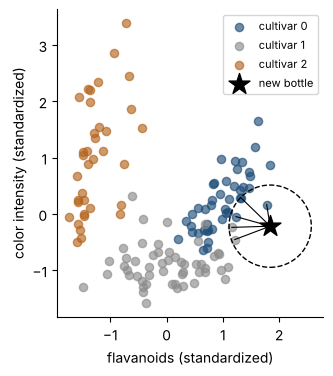

In [3]:
palette = {0: BLUE, 1: GRAY, 2: "#B5651D"}
for cls in [0, 1, 2]:
    mask = (y_train == cls).values
    plt.scatter(Z_train[mask, 0], Z_train[mask, 1], color=palette[cls], alpha=0.65, s=35, label=f"cultivar {cls}")
for i in nearest:
    plt.plot([new_bottle[0], Z_train[i, 0]], [new_bottle[1], Z_train[i, 1]], color="black", linewidth=0.8)
circle = plt.Circle(new_bottle, dist[nearest[-1]], fill=False, linestyle="--", color="black")
plt.gca().add_patch(circle)
plt.scatter(*new_bottle, marker="*", s=250, color="black", zorder=5, label="new bottle")
plt.gca().set_aspect("equal"); plt.xlabel("flavanoids (standardized)"); plt.ylabel("color intensity (standardized)")
plt.legend(loc="upper right", fontsize=8); plt.show()

**Giải thích từng dòng**

- `palette = {0: BLUE, 1: GRAY, 2: "#B5651D"}`: từ điển gán màu cho ba giống: xanh đậm, xám, và một màu nâu đất dịu để phân biệt.
- `mask = (y_train == cls).values`: (đã học) mặt nạ Đúng/Sai chọn các chai thuộc giống `cls`.
- `plt.scatter(Z_train[mask, 0], Z_train[mask, 1], ...)`: vẽ các điểm của giống đó: cột 0 làm hoành độ, cột 1 làm tung độ.
- `plt.plot([x1, x2], [y1, y2], ...)`: kẻ đường nối chai mới với từng hàng xóm: danh sách hai hoành độ, danh sách hai tung độ.
- `plt.Circle(new_bottle, dist[nearest[-1]], fill=False, ...)`: **mới:** `plt.Circle(tâm, bán_kính)` tạo hình tròn; bán kính là khoảng cách tới hàng xóm *xa nhất trong năm*; `fill=False` để chỉ vẽ viền. `plt.gca().add_patch(...)` gắn hình tròn vào khung hình.
- `plt.scatter(*new_bottle, marker="*", ...)`: `*new_bottle` là cách "rải" mảng hai số thành hai tham số `x`, `y`. Chai mới vẽ bằng ngôi sao đen.

**Cách đọc**

- **Con số:** năm chai gần nhất cách chai mới từ **0,39** đến **0,73** (đơn vị: độ lệch chuẩn). Giống của năm hàng xóm: **[0, 0, 1, 1, 0]**, tức phiếu chia **3 giống 0, 2 giống 1**. Máy đoán giống 0, nhưng chai mới thật sự thuộc giống **1**: **máy đoán sai**.
- **Bức tranh:** ba đám điểm tách khá rõ nhưng đám xám (giống 1) và đám xanh (giống 0) **giáp nhau**. Ngôi sao đen nằm đúng ở vùng giáp ranh, vòng tròn đứt phủ lên cả hai màu: năm hàng xóm không đồng thuận.
- **Ý nghĩa:** thất bại này *có ích*. Phiếu **3-2** là dấu hiệu **lưỡng lự**; nếu chia 5-0 ta yên tâm. Phần trăm phiếu chính là **mức chắc chắn** (`predict_proba` của k-NN, chặng 2). Máy biết mình đang không chắc, miễn là ta chịu *hỏi* thay vì chỉ nghe nhãn.

**Thuật toán k-NN, ba bước:** (1) đo khoảng cách từ chai mới đến *mọi* chai đã biết; (2) lấy **k chai gần nhất**; (3) **bỏ phiếu**, nhóm nào nhiều phiếu nhất thì thắng. Hết, không có "học" gì cả.

**Mang về chặng 1:** k-NN đoán nhóm của một điểm mới bằng cách hỏi **k điểm gần nhất** và bỏ phiếu. "Gần" đo bằng khoảng cách trên các cột.

## Chặng 2: `KNeighborsClassifier`, `fit` chỉ nhớ, hồ sơ mô hình

**Câu hỏi:** sklearn làm đúng như ta vừa làm tay không, và cái gì được "học"?

In [4]:
from sklearn.neighbors import KNeighborsClassifier
knn2 = KNeighborsClassifier(n_neighbors=5).fit(Z_train, y_train)
dists, idxs = knn2.kneighbors(new_bottle.reshape(1, -1))
print("kneighbors -> distances:", dists[0].round(2), "| positions:", idxs[0], "(same as ours:", bool((np.sort(idxs[0]) == np.sort(nearest)).all()), ")")
print("predict       :", knn2.predict(new_bottle.reshape(1, -1)))
print("predict_proba :", knn2.predict_proba(new_bottle.reshape(1, -1)).round(2), "(classes", knn2.classes_, ")")
print("has coef_?    :", hasattr(knn2, "coef_"), "| has intercept_?:", hasattr(knn2, "intercept_"))

kneighbors -> distances: [0.39 0.63 0.67 0.68 0.73] | positions: [ 23 123 121 128  17] (same as ours: True )
predict       : [0]
predict_proba : [[0.6 0.4 0. ]] (classes [0 1 2] )
has coef_?    : False | has intercept_?: False


**Giải thích từng dòng**

- `from sklearn.neighbors import KNeighborsClassifier`: **mới:** máy k-NN dùng cho **phân loại** nằm ở module `neighbors` (láng giềng).
- `KNeighborsClassifier(n_neighbors=5).fit(Z_train, y_train)`: `n_neighbors` chính là **k**: mặc định 5. `fit` ở đây **chỉ cất dữ liệu học vào bộ nhớ** (kèm một cấu trúc chỉ mục để tra nhanh), không tính ra hệ số nào.
- `new_bottle.reshape(1, -1)`: sklearn đòi `X` luôn là **bảng hai chiều**; một chai đơn lẻ chỉ là mảng một chiều. `reshape(1, -1)` đổi thành "1 dòng, số cột tự suy".
- `knn2.kneighbors(...)`: **mới:** cho biết **k hàng xóm** của điểm hỏi: trả về hai mảng gồm khoảng cách và vị trí của họ trong tập học. Đây là cách *mở nắp nhìn bên trong* k-NN.
- `np.sort(idxs[0]) == np.sort(nearest)`: so với kết quả làm tay (sắp xếp cả hai về cùng thứ tự rồi so từng phần tử).
- `knn2.predict_proba(...)`: **tỉ lệ phiếu** cho từng giống, thứ tự theo `classes_`. Với k = 5 chỉ có thể là bội của 0,2.
- `hasattr(knn2, "coef_")`: `hasattr(đối_tượng, "tên")` hỏi "đối tượng có thuộc tính này không"? Kiểm chứng rằng k-NN **không có `coef_` hay `intercept_`**: không có công thức nào để đọc.

**Cách đọc:** sklearn tìm ra **đúng năm chai ta tìm bằng tay**, bỏ phiếu cho ra giống **0** với tỉ lệ phiếu [0.6, 0.4, 0.0] (phiếu chia 3-2, mức chắc chắn thấp). Điểm khác lớn nhất so với B và C1: **không có `coef_`, không có `intercept_`**. Mọi "kiến thức" của k-NN *chính là dữ liệu học*, nên người ta gọi nó là **học lười** (lazy learning): `fit` gần như tức thì, còn mỗi lần `predict` phải đi tra cứu.

**Hồ sơ của mô hình:**

| Mục | `KNeighborsClassifier` |
|---|---|
| **Nó là gì** | Bỏ phiếu của k điểm gần nhất trong tập học |
| **Dùng khi nào** | Dữ liệu vừa phải (vài nghìn dòng), ít cột có ích, ranh giới giữa nhóm cong cũng được; cần một mốc đơn giản để so |
| **`X`** | Bảng **toàn số**; **phải cùng thang đo** (chặng 3) |
| **`y`** | Nhãn nhóm (số hoặc chữ) |
| **Ô trống `NaN` trong `X`** | **Không chịu** (không đo được khoảng cách): điền hoặc bỏ trước |
| **Module sklearn** | `sklearn.neighbors.KNeighborsClassifier` |
| **`fit` / `predict`** | `fit` chỉ cất dữ liệu; `predict` tra k hàng xóm; `predict_proba` cho tỉ lệ phiếu; `kneighbors` cho hàng xóm cụ thể |
| **Sau `fit` có gì** | Không có `coef_`, `intercept_`; có `classes_`, `n_features_in_` |
| **Siêu tham số chính** | `n_neighbors` (k), `weights`, `metric` / `p` |

**Mang về chặng 2:** k-NN không có công thức để đọc: nó là **trí nhớ có tra cứu**. `predict_proba` là tỉ lệ phiếu; `kneighbors` cho thấy hàng xóm cụ thể, nên *giải thích được từng ca* ("vì chai này giống mấy chai kia").

## Chặng 3: Thang đo phá k-NN, một cột lấn át mười hai cột còn lại

**Câu hỏi:** ta vừa đo khoảng cách bằng cách cộng bình phương hiệu của các cột. Nếu một cột có số to hơn hẳn các cột khác thì sao?

Xem các cột của rượu: độ cồn nằm quanh 11 đến 15, nhưng **proline** nằm từ 278 đến 1680. Hiệu 100 đơn vị proline *chẳng đáng kể*, nhưng bình phương lên là 10.000, **át hẳn** hiệu 1 độ cồn (bình phương là 1).

In [5]:
spread = X.describe().loc[["min", "max", "std"]].T.round(2)
print(spread.sort_values("std", ascending=False).head(4).to_string())
print("...")
print(spread.sort_values("std").head(3).to_string())

                      min     max     std
proline            278.00  1680.0  314.91
magnesium           70.00   162.0   14.28
alcalinity_of_ash   10.60    30.0    3.34
color_intensity      1.28    13.0    2.32
...
                       min   max   std
nonflavanoid_phenols  0.13  0.66  0.12
hue                   0.48  1.71  0.23
ash                   1.36  3.23  0.27


**Giải thích từng dòng**

- `X.describe().loc[["min", "max", "std"]].T.round(2)`: (đã học ở A2) bảng thống kê rồi chọn ba hàng min, max, độ lệch chuẩn (`std`); `.T` đảo hàng và cột để mỗi cột đề thành một dòng.
- `spread.sort_values("std", ascending=False).head(4)`: sắp theo `std` giảm dần, lấy bốn cột có độ biến thiên lớn nhất. `.sort_values(tên_cột)` sắp theo cột chỉ định.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
raw_knn = KNeighborsClassifier(n_neighbors=5)
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
raw_scores = cross_val_score(raw_knn, X_train, y_train, cv=cv)
scaled_scores = cross_val_score(scaled_knn, X_train, y_train, cv=cv)
print(f"k-NN on raw columns   : accuracy {raw_scores.mean():.3f}  (spread {raw_scores.std():.3f})")
print(f"k-NN on scaled columns: accuracy {scaled_scores.mean():.3f}  (spread {scaled_scores.std():.3f})")
from sklearn.dummy import DummyClassifier
print(f"lazy machine          : accuracy {cross_val_score(DummyClassifier(strategy='most_frequent'), X_train, y_train, cv=cv).mean():.3f}")

k-NN on raw columns   : accuracy 0.691  (spread 0.061)
k-NN on scaled columns: accuracy 0.957  (spread 0.032)
lazy machine          : accuracy 0.399


**Giải thích từng dòng**

- `cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)`: (đã học ở C1) 50 điểm số mỗi lần đo.
- `scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))`: pipeline: chuẩn hóa 13 cột rồi k-NN. Mỗi lần kiểm định chéo, bộ chuẩn hóa chỉ học từ phần học của lần đó.
- `cross_val_score(raw_knn, X_train, y_train, cv=cv)`: (đã học) 50 điểm độ đúng.

In [7]:
bottle_a, bottle_b = X_train.iloc[0], X_train.iloc[1]
diff = (bottle_a - bottle_b) ** 2
share = (diff / diff.sum()).sort_values(ascending=False)
print("squared differences between two bottles, as a share of their total distance^2:")
for name, value in share.head(3).items():
    print(f"  {name:20s}{100 * value:5.1f} %")

squared differences between two bottles, as a share of their total distance^2:
  proline              99.9 %
  magnesium             0.1 %
  alcalinity_of_ash     0.0 %


**Giải thích từng dòng**

- `bottle_a, bottle_b = X_train.iloc[0], X_train.iloc[1]`: (đã học `iloc`) hai chai học đầu tiên, giữ nguyên thang đo gốc.
- `diff = (bottle_a - bottle_b) ** 2`: bình phương hiệu từng cột: mỗi cột đóng góp bao nhiêu vào khoảng cách bình phương.
- `share = (diff / diff.sum()).sort_values(ascending=False)`: đổi sang **tỉ lệ đóng góp** của từng cột rồi sắp giảm dần.
- `for name, value in share.head(3).items():`: `.items()` cho từng cặp (tên cột, giá trị) của một dãy pandas; in ba cột đóng góp nhiều nhất. `:20s` canh chữ trong 20 ký tự, `:5.1f` số có 1 chữ số lẻ trong 5 ký tự.

**Cách đọc**

- **Con số:** cột **proline** có độ lệch chuẩn khoảng **315**, gấp hàng trăm lần cột `hue` (0,23). Trên cột thô, k-NN đạt độ đúng **0,691**; sau khi chuẩn hóa nhảy lên **0,957**. Máy lười chỉ **0,399**. Với hai chai ở cuối, riêng cột proline chiếm khoảng **99,9%** khoảng cách.
- **Bức tranh:** khi không chuẩn hóa, "bản đồ" của k-NN thực chất chỉ còn **một trục** (proline) và mười hai trục kia gần như bị nén dẹt. Hàng xóm được chọn *theo proline*, bỏ qua mọi thông tin khác.
- **Ý nghĩa:** với k-NN, **chuẩn hóa là bắt buộc**, không phải tùy chọn. Cùng họ "nhạy thang đo" với Ridge và Lasso (B4, B6). Ngược lại, hồi quy thường (B1 đến B3) thì không nhạy, vì máy tự điều chỉnh hệ số cho từng cột.
- **Cũng nhớ:** trong pipeline, bộ chuẩn hóa **học từ tập học** rồi áp cho chai mới; nếu chuẩn hóa *cả* tập thi cùng tập học, ta đã gian lận (rò rỉ, A4).

**Mang về chặng 3:** k-NN đo khoảng cách nên cột có số lớn sẽ át cột khác. **Luôn chuẩn hóa** (`StandardScaler`) trước k-NN, đặt trong `make_pipeline`.

## Chặng 4: Chọn k, nhớ cả nhiễu hay bỏ phiếu cả vườn

**Câu hỏi:** hỏi 1 hàng xóm, 5 hàng xóm hay 50 hàng xóm?

- **k = 1:** chỉ tin *một* chai gần nhất. Nếu chai đó là ngoại lệ (đóng nhầm nhãn, hay đo lỗi) thì ta sai theo. Máy **nhớ cả nhiễu**: điểm trên tập học luôn đúng (vì hàng xóm gần nhất của một chai học chính là nó), nhưng tập thi thì bấp bênh. Đây là **quá khớp** của k-NN.
- **k rất lớn:** hỏi cả vườn, bao gồm những chai ở xa chẳng liên quan. Ranh giới nhòe, máy **bỏ qua cấu trúc**. Đây là **dưới khớp**.

Ta quét k và đo bằng kiểm định chéo lặp **chỉ trên tập học** (A4: không nhìn tập thi để chọn):

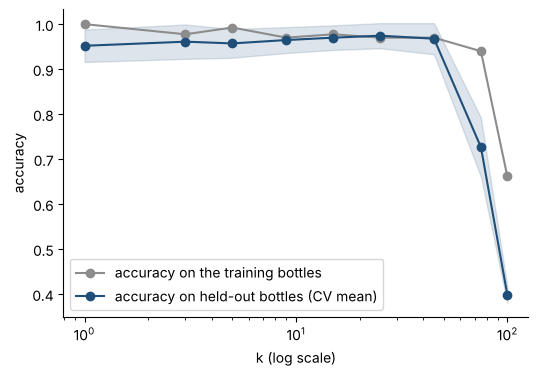

  k  train  CV mean  CV std
  1  1.000    0.952   0.036
  3  0.977    0.961   0.038
  5  0.992    0.957   0.032
  9  0.970    0.965   0.029
 15  0.977    0.970   0.027
 25  0.970    0.974   0.028
 45  0.970    0.968   0.035
 75  0.940    0.726   0.066
100  0.662    0.399   0.019


In [8]:
ks = [1, 3, 5, 9, 15, 25, 45, 75, 100]
cv_mean, cv_std, train_acc = [], [], []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    s = cross_val_score(m, X_train, y_train, cv=cv)
    cv_mean.append(s.mean()); cv_std.append(s.std())
    train_acc.append(m.fit(X_train, y_train).score(X_train, y_train))
cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)
plt.plot(ks, train_acc, "o-", color=GRAY, label="accuracy on the training bottles")
plt.plot(ks, cv_mean, "o-", color=BLUE, label="accuracy on held-out bottles (CV mean)")
plt.fill_between(ks, cv_mean - cv_std, cv_mean + cv_std, color=BLUE, alpha=0.15)
plt.xscale("log"); plt.xlabel("k (log scale)"); plt.ylabel("accuracy"); plt.legend(loc="lower left")
plt.show()
print(pd.DataFrame({"k": ks, "train": np.round(train_acc, 3), "CV mean": cv_mean.round(3), "CV std": cv_std.round(3)}).to_string(index=False))

**Giải thích từng dòng**

- `ks = [1, 3, 5, 9, 15, 25, 45, 75, 100]`: các giá trị k thử, từ ít đến rất nhiều.
- `m.fit(X_train, y_train).score(X_train, y_train)`: độ đúng **trên chính tập học** (điểm "tự chấm"). `.fit(...)` trả về chính `m` nên nối tiếp `.score` được.
- `plt.fill_between(ks, cv_mean - cv_std, cv_mean + cv_std, ...)`: **mới:** tô một **dải** giữa hai đường (trung bình trừ độ lệch chuẩn và trung bình cộng độ lệch chuẩn): cho thấy điểm số **dao động** ra sao giữa các lần chia.
- `plt.xscale("log")`: (đã học) trục k theo thang log vì ta thử k từ 1 đến 100.

**Cách đọc**

- **Con số:** với k = 1 độ đúng trên tập học là **1,000** (hiển nhiên, mỗi chai tự là hàng xóm gần nhất của mình) còn trên chai chưa gặp **0,952**. Điểm kiểm định chéo cao nhất ở k = **25** (**0,974**), nhưng cả vùng từ k = 3 đến 45 đều nằm trong khoảng 0,957 đến 0,974. Với k = 75 điểm **tụt** xuống 0,726 và với k = 100 chỉ còn 0,399.
- **Bức tranh:** đường xanh có hình **cao nguyên rồi vách đứng**: ở giữa phẳng và cao, bên phải *rơi thẳng xuống*. Chỗ rơi không ngẫu nhiên: giống nho nhỏ nhất chỉ có **36** chai trong tập học (và ít hơn nữa trong mỗi phần học của kiểm định chéo). Khi k lớn hơn cỡ nhóm nhỏ nhất, **đám đông các giống lớn luôn thắng phiếu** dù chai mới ở ngay giữa đám nhóm nhỏ.
- **Ý nghĩa:** quy tắc thực hành: **k nhỏ hơn cỡ nhóm nhỏ nhất rất nhiều**, thường chọn **số lẻ** để tránh hòa phiếu giữa hai nhóm. Và đừng tôn thờ k tốt nhất: vùng cao nguyên rộng nghĩa là *chọn k = 5 hay k = 15 đều ổn*; chênh vài phần nghìn nằm trong vùng nhiễu (dải mờ).
- **Nhớ lại A4:** ta chọn k bằng kiểm định chéo trên tập học; tập thi chưa mở.

Xem ranh giới thay đổi theo k. Ta quay lại **hai cột** để vẽ được (độ đúng sẽ thấp hơn mười ba cột, bình thường):

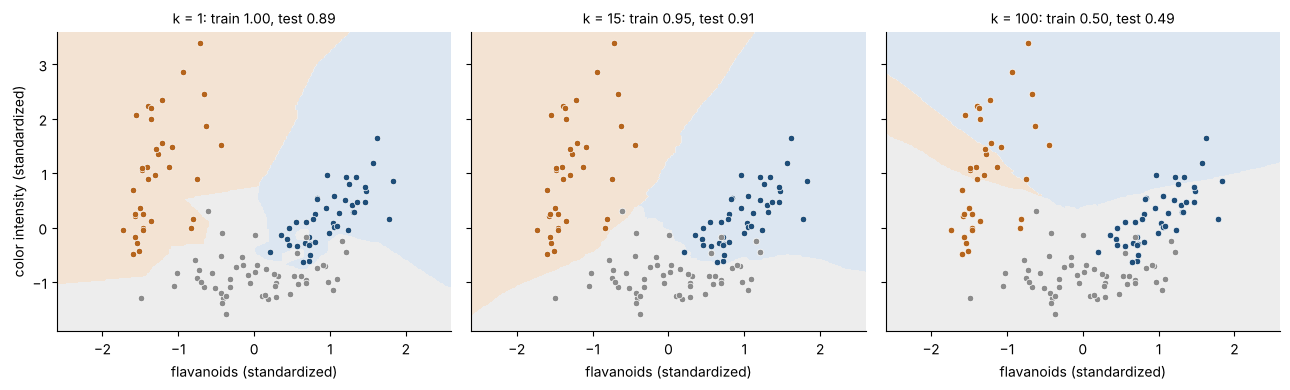

In [9]:
def draw_knn_map(k, ax):
    m = KNeighborsClassifier(n_neighbors=k).fit(Z_train, y_train)
    xx, yy = np.meshgrid(np.linspace(-2.6, 2.6, 250), np.linspace(-1.9, 3.6, 250))
    zone = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zone, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#DCE6F1", "#EDEDED", "#F3E3D3"])
    for cls in [0, 1, 2]:
        mask = (y_train == cls).values
        ax.scatter(Z_train[mask, 0], Z_train[mask, 1], color=palette[cls], s=22, edgecolor="white", linewidth=0.5)
    ax.set_title(f"k = {k}: train {m.score(Z_train, y_train):.2f}, test {m.score(Z_test, y_test):.2f}", fontsize=10)
    ax.set_xlabel("flavanoids (standardized)")
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, k in zip(axes, [1, 15, 100]):
    draw_knn_map(k, ax)
axes[0].set_ylabel("color intensity (standardized)")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `def draw_knn_map(k, ax):`: hàm vẽ "bản đồ vùng đoán" của k-NN với k cho trước vào khung `ax`.
- `zone = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)`: (như C1) hỏi mô hình đoán gì ở mỗi điểm lưới; lần này dùng `predict` (nhãn 0, 1, 2) thay vì xác suất.
- `ax.contourf(xx, yy, zone, levels=[-0.5, 0.5, 1.5, 2.5], colors=[...])`: ba vùng tô màu nhạt cho ba nhãn: các mốc cắt nằm *giữa* các số nguyên để nhãn 0, 1, 2 mỗi cái rơi gọn vào một vùng.
- `ax.scatter(...)`: (đã học) chấm các chai học lên, tô theo giống bằng `palette` ở chặng 1.
- `m.score(Z_train, y_train)`: độ đúng trên tập học (chưa phải số để chọn k, chỉ để xem).
- `for ax, k in zip(axes, [1, 15, 100]):`: ba khung cạnh nhau: k = 1 (nhớ nhiễu), 15 (vừa), 100 (bỏ phiếu cả vườn).

**Cách đọc**

- **Con số (hai cột):** k = 1: train **1,00**, test **0,89**. k = 15: train **0,95**, test **0,91**. k = 100: train **0,50**, test **0,49**.
- **Bức tranh:** ở **k = 1** ranh giới *gai góc*, có những "đảo" nhỏ quanh từng điểm lẻ (những chỗ máy nhớ cả nhiễu). Ở **k = 15** ranh giới *trơn*, ba vùng gọn gàng theo ba đám. Ở **k = 100** vùng của giống đông nhất (xám) **lấn chiếm** cả phần đất của hai giống kia, ranh giới méo mó: phiếu của cả vườn đè bẹp cấu trúc.
- **Ý nghĩa:** `k` là **núm vặn độ trơn của ranh giới**: nhỏ thì uốn theo từng điểm (nhiều phương sai, ít thiên lệch), lớn thì mượt đến mức bỏ lỡ chi tiết. Đây là *cùng một bài học* như `degree` ở B5, `alpha` ở B6 và `C` ở C1, trong hình hài khác.

**Mang về chặng 4:** `n_neighbors` (k) nhỏ thì nhớ cả nhiễu (quá khớp), lớn thì nhòe (dưới khớp). Chọn k bằng kiểm định chéo trên tập học, ưu tiên số lẻ và vùng cao nguyên.

## Chặng 5: Đo khoảng cách kiểu nào, phiếu của ai nặng hơn

**Câu hỏi:** ngoài k, còn hai núm vặn nào?

- **`p`** (hay `metric`): cách đo khoảng cách. `p = 2` là **Euclid** (đường chim bay). `p = 1` là **Manhattan** (đi theo đường ô bàn cờ, cộng độ lệch từng cột, không bình phương). Khoảng cách Manhattan **ít bị một cột lệch quá nặng làm chao đảo** hơn.
- **`weights`**: `"uniform"` (mặc định) là mỗi hàng xóm một phiếu như nhau; `"distance"` là hàng xóm **gần hơn thì phiếu nặng hơn** (nặng theo nghịch đảo khoảng cách).

In [10]:
contenders = {
    "Euclid, equal votes (default)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9)),
    "Euclid, closer = heavier":      make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9, weights="distance")),
    "Manhattan, equal votes":        make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9, p=1)),
    "Chebyshev (max difference)":    make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9, metric="chebyshev")),
}
rows = {}
for name, m in contenders.items():
    s = cross_val_score(m, X_train, y_train, cv=cv)
    rows[name] = {"CV mean": s.mean(), "CV std": s.std()}
print(pd.DataFrame(rows).T.round(3).to_string())

                               CV mean  CV std
Euclid, equal votes (default)    0.965   0.029
Euclid, closer = heavier         0.965   0.029
Manhattan, equal votes           0.979   0.024
Chebyshev (max difference)       0.933   0.049


**Giải thích từng dòng**

- `contenders = {...}`: từ điển bốn ứng viên: cùng k = 9, chỉ đổi cách đo hay cách tính phiếu.
- `KNeighborsClassifier(n_neighbors=9, weights="distance")`: **mới:** phiếu nặng theo độ gần.
- `KNeighborsClassifier(n_neighbors=9, p=1)`: **mới:** `p = 1` là khoảng cách Manhattan (mặc định `p = 2` là Euclid).
- `KNeighborsClassifier(n_neighbors=9, metric="chebyshev")`: khoảng cách **Chebyshev**: chỉ lấy *cột lệch nhiều nhất*, bỏ qua mọi cột khác. Một biến thể để thấy thay đổi cách đo ảnh hưởng ra sao.
- `pd.DataFrame(rows).T.round(3)`: (đã học) từ điển các từ điển thành bảng; `.T` để mỗi ứng viên một dòng.

**Cách đọc**

- **Con số:** Euclid mặc định **0,965**, phiếu theo khoảng cách **0,965**, Manhattan **0,979**, Chebyshev **0,933**. Độ lệch chuẩn quanh 0,02 đến 0,05.
- **Bức tranh:** ba cách đầu *chen sát nhau* ở khoảng 0,96 đến 0,98; Chebyshev, cách đo chỉ nhìn một cột lệch nhiều nhất và bỏ phí phần còn lại, thấp nhất, nhưng hụt cũng chỉ khoảng một độ lệch chuẩn.
- **Ý nghĩa:** cách đo và cách tính phiếu ít quan trọng hơn **chuẩn hóa** (chặng 3, độ đúng tăng hơn 0,25) và **số cột thừa** (chặng 6). Đây là *núm vặn tinh chỉnh*; đừng mất cả buổi để chọn giữa Euclid và Manhattan khi chênh lệch (0,01 đến 0,02) nằm trong độ lệch chuẩn.
- **Một điều thành thật:** Manhattan nhỉnh hơn một chút ở bộ dữ liệu này, nhưng bộ khác có thể ngược lại. Chọn bằng kiểm định chéo, và chỉ chọn cái khác mặc định khi lợi rõ.

**Mang về chặng 5:** ba núm vặn: `n_neighbors` (chủ chốt), `p` hoặc `metric` (cách đo), `weights` (phiếu nặng nhẹ). Đừng quá tỉ mỉ vì chênh nhỏ thường là nhiễu.

## Chặng 6: Giới hạn, cột nhiễu làm hàng xóm lạc đường

**Câu hỏi:** thêm cột thì có luôn tốt không?

Với hồi quy, thêm một cột vô ích thường chỉ bị hệ số gần 0 "vô hiệu hóa" (tuy vẫn thêm nhiễu: B3, B5). Với k-NN thì khác: **mọi cột đều có phiếu ngang nhau** trong phép đo khoảng cách. Thử cho thêm vào các cột **toàn nhiễu ngẫu nhiên** (không liên quan giống nho) và xem điểm số.

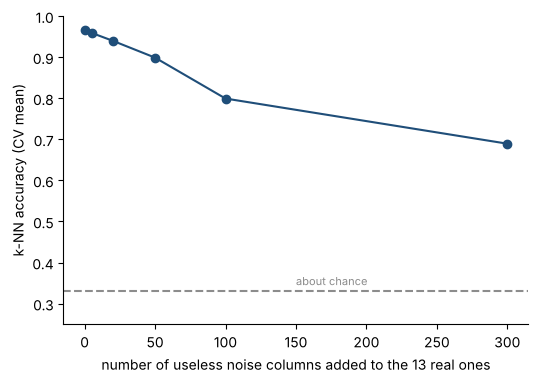

{0: 0.965, 5: 0.959, 20: 0.94, 50: 0.899, 100: 0.799, 300: 0.689}


In [11]:
rng = np.random.default_rng(0)
n_noise = [0, 5, 20, 50, 100, 300]
noise_scores = []
for n in n_noise:
    noisy = np.c_[StandardScaler().fit_transform(X), rng.normal(size=(len(X), n))]
    noise_scores.append(cross_val_score(KNeighborsClassifier(n_neighbors=5), noisy, y, cv=cv).mean())
plt.plot(n_noise, noise_scores, "o-", color=BLUE)
plt.axhline(0.33, color=GRAY, linestyle="--"); plt.text(150, 0.345, "about chance", fontsize=8, color=GRAY)
plt.xlabel("number of useless noise columns added to the 13 real ones"); plt.ylabel("k-NN accuracy (CV mean)")
plt.ylim(0.25, 1.0); plt.show()
print({n: round(float(sc), 3) for n, sc in zip(n_noise, noise_scores)})

**Giải thích từng dòng**

- `rng = np.random.default_rng(0)`: bộ sinh số ngẫu nhiên có hạt giống (đã học).
- `noisy = np.c_[StandardScaler().fit_transform(X), rng.normal(size=(len(X), n))]`: ghép bảng 13 cột thật (đã chuẩn hóa) với `n` cột **số ngẫu nhiên thuần túy** (`rng.normal` tạo số theo chuông chuẩn). `fit_transform` là gộp `fit` rồi `transform`. Lưu ý: để thí nghiệm nhanh gọn ta chuẩn hóa trước toàn bộ; trong dự án thật phải đặt chuẩn hóa vào pipeline.
- `cross_val_score(KNeighborsClassifier(n_neighbors=5), noisy, y, cv=cv).mean()`: độ đúng kiểm định chéo cho từng số lượng cột nhiễu.
- `plt.axhline(0.33, ...)`: ba giống khá đều nhau nên đoán bừa trúng khoảng một phần ba (thật ra mốc lười là 0,40 do giống B đông nhất; vạch này chỉ để định hướng).

**Cách đọc**

- **Con số:** không thêm cột nhiễu: **0,965**. Thêm 20 cột nhiễu: **0,940**. Thêm 100: **0,799**. Thêm 300: **0,689**.
- **Bức tranh:** đường xanh **trượt dốc đều** từ gần 0,97 xuống 0,7. Mười ba cột thật mang thông tin; hàng trăm cột nhiễu thêm vào *làm loãng* khoảng cách: hai chai cùng giống vẫn gần nhau ở 13 cột thật nhưng xa nhau ở hàng trăm cột nhiễu, nên "hàng xóm" bị chọn gần như ngẫu nhiên.
- **Ý nghĩa:** đây là một mặt của **"lời nguyền số chiều"** (curse of dimensionality): nhiều cột mà ít dữ liệu thì "gần" mất nghĩa. k-NN **cần ít cột, mà là cột có ích**. Hồi quy logistic (C1) hay cây (C5) tự "phớt lờ" cột vô ích tốt hơn nhiều.

**Ba giới hạn nữa của k-NN:**

1. **Chậm khi dữ liệu lớn:** mỗi lần `predict` phải so với (gần) mọi chai học. Với hàng triệu dòng nên dùng mô hình khác.
2. **Không ngoại suy:** chai mới *ở rất xa* mọi chai đã biết vẫn nhận một giống (từ hàng xóm "gần nhất" dù rất xa) mà không có cảnh báo.
3. **Không có công thức để đọc:** giải thích được từng ca (xem hàng xóm) nhưng không tổng kết được "cột nào quan trọng".

## Phán quyết và bài học nghề

**Phán quyết cho anh Tú.** Dùng k-NN trên **13 cột đã chuẩn hóa** với k khoảng 9 đến 15: đoán đúng khoảng **97 chai trên 100** (kiểm định chéo), tốt hơn hẳn mốc lười (0,40). Chai mới nào có **phiếu bầu chia rẽ** (ví dụ 5-4) nên đưa chuyên gia xem. Bạn có thể giải thích với khách: *"chai này giống mấy chai kia nhất"*, rất dễ nghe.

**Bài học nghề.**

1. **k-NN = tìm k điểm gần nhất rồi bỏ phiếu.** `fit` chỉ nhớ; không có `coef_`.
2. **Phải chuẩn hóa**: cột số lớn át các cột khác (độ đúng 0,69 lên 0,96).
3. **`n_neighbors` là núm vặn độ trơn:** k = 1 nhớ cả nhiễu, k quá lớn nhòe; chọn bằng kiểm định chéo, ưu tiên số lẻ.
4. **Cột thừa làm hàng xóm lạc đường:** chọn cột có ích trước.
5. **Ít phụ thuộc** núm `p` và `weights` hơn là vào chuẩn hóa và số cột.
6. **Mốc tốt để so sánh**: một mô hình phức tạp khó có lý do tồn tại nếu thua k-NN đơn giản.

**Một điều thành thật:** bộ dữ liệu rượu *rất sạch và dễ* (ba giống tách rõ), nên k-NN chạy đẹp. Với dữ liệu bẩn, nhiều cột nhiễu hơn, độ đúng thường thấp hơn nhiều.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | k-NN: tìm k điểm gần nhất rồi bỏ phiếu; khoảng cách thường là Euclid. |
| 2 | `fit` chỉ nhớ dữ liệu, không có `coef_`; `kneighbors` cho thấy hàng xóm; `predict_proba` là tỉ lệ phiếu. |
| 3 | Phải chuẩn hóa: cột số lớn át các cột khác (0,69 lên 0,96). |
| 4 | k nhỏ nhớ cả nhiễu (quá khớp), k lớn nhòe (dưới khớp); chọn bằng kiểm định chéo. |
| 5 | `p` và `weights` chỉ là tinh chỉnh; chênh nhỏ thường là nhiễu. |
| 6 | Cột nhiễu, dữ liệu lớn và điểm quá xa là điểm yếu của k-NN. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Hỏi vài hàng xóm giống nhất rồi bỏ phiếu | k láng giềng gần nhất | `KNeighborsClassifier` |
| Số hàng xóm được hỏi | k (siêu tham số) | `n_neighbors=` |
| Đường chim bay giữa hai điểm | khoảng cách Euclid | `p=2` (mặc định) |
| Đi theo ô bàn cờ | khoảng cách Manhattan | `p=1` |
| Hàng xóm gần thì phiếu nặng | trọng số theo khoảng cách | `weights="distance"` |
| Xem cụ thể hàng xóm của một điểm | tra láng giềng | `model.kneighbors(...)` |
| Học chỉ là nhớ | học lười (lazy learning) | `fit` không tính `coef_` |
| Đưa mọi cột về cùng thang đo | chuẩn hóa | `StandardScaler` |
| Nhiều cột thừa khiến "gần" mất nghĩa | lời nguyền số chiều | thêm cột nhiễu |

**Thử thách tự làm**

1. Ở chặng 1, thử lấy chai thi thứ 10 (`Z_test[9]`) và k = 3, 5, 9, 15. Giống đoán có đổi không? Phiếu chia thế nào?
2. Ở chặng 3, chuẩn hóa chỉ **bốn cột** có `std` lớn nhất bằng `ColumnTransformer` (đã học ở B4) và để nguyên các cột còn lại. Độ đúng thế nào? Vì sao?
3. Kể chuyện với dữ liệu khác: dùng `load_iris` (ba loài, 4 cột). Tìm k tốt nhất bằng kiểm định chéo, vẽ ranh giới với hai cột cánh hoa. So với hồi quy logistic ở C1.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Mô tả ba bước của k-NN bằng lời đời thường.
- [ ] Giải thích vì sao `fit` của k-NN không có `coef_`.
- [ ] Giải thích vì sao phải chuẩn hóa và cho ví dụ số.
- [ ] Chọn k bằng kiểm định chéo và đọc được hình quá khớp/dưới khớp.
- [ ] Phân biệt `p`, `weights`, `metric`.
- [ ] Nêu ba giới hạn của k-NN.

## Phần thưởng (Tip pro): k-NN cho bài hồi quy, và vì sao nó "khớp từng bậc"


Đổi một chữ là k-NN thành mô hình **hồi quy**: `KNeighborsRegressor` lấy **trung bình** giá trị của k hàng xóm thay vì bỏ phiếu. Vì vậy đường dự đoán của nó **bậc thang** (mỗi vùng một mức) thay vì mượt như đường thẳng của B1. Mọi lời khuyên ở trên vẫn đúng: phải chuẩn hóa, k nhỏ thì nhớ cả nhiễu, k lớn thì nhòe. Hãy thử với bài chị Hạnh ở B1: dùng cột `bmi` đoán `target` và so với đường thẳng.

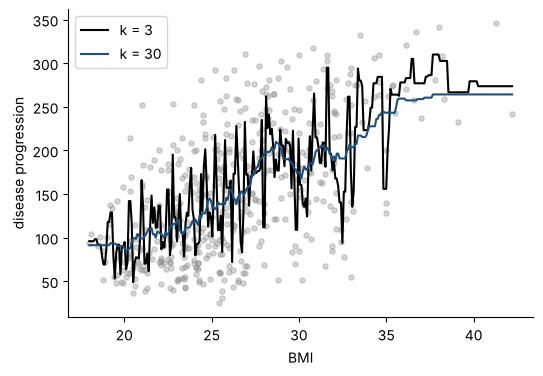

In [12]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.datasets import load_diabetes
d = load_diabetes(as_frame=True, scaled=False).frame
bx = d[["bmi"]]; by = d["target"]
gx = pd.DataFrame({"bmi": np.linspace(bx["bmi"].min(), bx["bmi"].max(), 300)})
plt.scatter(bx["bmi"], by, color=GRAY, alpha=0.35, s=14)
for k, c in [(3, "black"), (30, BLUE)]:
    plt.plot(gx["bmi"], KNeighborsRegressor(n_neighbors=k).fit(bx, by).predict(gx), color=c, label=f"k = {k}")
plt.xlabel("BMI"); plt.ylabel("disease progression"); plt.legend(); plt.show()

**Giải thích từng dòng**

- `KNeighborsRegressor(n_neighbors=k).fit(bx, by).predict(gx)`: bản hồi quy của k-NN: dự đoán là **trung bình `target` của k bệnh nhân có BMI gần nhất**. (Một cột duy nhất nên không cần chuẩn hóa.)
- `for k, c in [(3, "black"), (30, BLUE)]:`: vẽ hai đường: k = 3 (gập ghềnh bám sát nhiễu) và k = 30 (trơn hơn).